# **Prescriptive Data Science – Assignment 1**
### **Optimal decision for the 50 largest IDX stocks (August 2026)**

In [2]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pds import config as C
from pds import data as D
from pds import features as F
from pds import v2 as V2
from pds import timing as T
from pds import portfolio as PF
from pds import backtest as B
from pds import simulate as SIM
from pds import figures as FG
from pds import viz as V

V.setup()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
idx = pd.IndexSlice

T0 = pd.Timestamp(C.DECISION_DATE)
T1 = pd.Timestamp(C.LIVE_DATE)
NOV30 = pd.Timestamp(C.LIVE_END)
print(f"Decision date {T0:%d-%b-%Y}")
print(f"Reality check to {C.EVAL_END}")
print(f"Live decision {T1:%d-%b-%Y} for {NOV30:%d-%b-%Y}")

Decision date 31-Aug-2026
Reality check to 2026-10-16
Live decision 19-Oct-2026 for 30-Nov-2026


In [ ]:
# 8 ranking signals (incl. ridge / tree-ensemble / LSTM forecasts and fundamental + macro composites),
# 3 optimizers, 2 covariance models, 2 signal strengths, 3 portfolio sizes and 4 cash overlays.
POLICY = {
    "K": 15,              # keep the 15 best-ranked investable names (52-week-high signal)
    "kappa": 0.03,        # Grinold-Kahn information coefficient: mu_i = kappa * sigma_i * z_i
    "lookback": 252,      # trading days of returns for the Ledoit-Wolf covariance

    # Division of the portfolio into 3 terciles by "paper market cap" (least liquid, mid, most liquid)
    "cap": 0.10,          # at most 10% per name
    "sector_cap": 0.30,   # at most 30% per sector
    "struct_cap": 0.15,   # at most 15% in the least liquid ("paper market cap") tercile
}

lock = json.load(open(C.LOCKED / "decision_v2_2026-08-31.json"))
winner = lock["winner"]
assert winner["signal"] == "high52"
assert winner["opt"] == "maxsharpe"
assert winner["cov"] == "lw"
assert winner["overlay"] == "timing_model"
assert all(float(winner[k]) == float(v) for k, v in POLICY.items())

print(f"Policy search: {lock['N_candidates']:,} candidates, selected by mean rank of the CRRA certainty equivalent in 2015-2023 and 2024-Jun 2026 (rule fixed before scoring)")
print(f"Probability of backtest overfitting (PBO) = {lock['PBO']:.0%}, deflated Sharpe ratio = {lock['DSR']['DSR']:.0%}")
print("Selected :")
print("52-week-high signal -> maximum Sharpe (Ledoit-Wolf) -> 10% per name")
print("30% per sector -> equity share from the cross-country crash model, rest in a money-market fund")

Policy search: 1,051 candidates, selected by mean rank of the CRRA certainty equivalent in 2015-2023 and 2024-Jun 2026 (rule fixed before scoring)
Probability of backtest overfitting (PBO) = 29%, deflated Sharpe ratio = 17%
Selected :
52-week-high signal -> maximum Sharpe (Ledoit-Wolf) -> 10% per name
30% per sector -> equity share from the cross-country crash model, rest in a money-market fund


## **1. Public data**

#### **Top 50 largest stocks on the IDX, August 2026**

In [9]:
# The 50 largest IDX stocks by market capitalization at the end of August 2026
TOP50_AUG2026 = [
    (1, "BBCA", "Bank Central Asia Tbk", 795_400.3),
    (2, "BBRI", "Bank Rakyat Indonesia (Persero) Tbk", 489_723.6),
    (3, "DCII", "DCI Indonesia Tbk", 476_987.6),
    (4, "BYAN", "Bayan Resources Tbk", 469_166.7),
    (5, "BREN", "Barito Renewables Energy Tbk", 444_148.0),
    (6, "BMRI", "Bank Mandiri (Persero) Tbk", 394_800.0),
    (7, "AMMN", "Amman Mineral Internasional Tbk", 313_545.8),
    (8, "MORA", "Mora Telematika Indonesia Tbk", 265_146.8),
    (9, "TLKM", "Telkom Indonesia (Persero) Tbk", 256_310.4),
    (10, "ASII", "Astra International Tbk", 191_616.3),
    (11, "DSSA", "Dian Swastatika Sentosa Tbk", 171_752.7),
    (12, "TPIA", "Chandra Asri Pacific Tbk", 169_038.1),
    (13, "SRAJ", "Sejahteraraya Anugrahjaya Tbk", 167_673.8),
    (14, "BRPT", "Barito Pacific Tbk", 167_275.5),
    (15, "BBNI", "Bank Negara Indonesia (Persero) Tbk", 143_366.6),
    (16, "EMAS", "Merdeka Gold Resources Tbk", 141_421.1),
    (17, "DNET", "Indoritel Makmur Internasional Tbk", 141_130.8),
    (18, "SMMA", "Sinar Mas Multiartha Tbk", 127_830.9),
    (19, "MPRO", "Maha Properti Indonesia Tbk", 121_547.1),
    (20, "BRMS", "Bumi Resources Minerals Tbk", 106_338.0),
    (21, "PANI", "Pantai Indah Kapuk Dua Tbk", 105_953.9),
    (22, "CASA", "Capital Financial Indonesia Tbk", 98_329.7),
    (23, "CUAN", "Petrindo Jaya Kreasi Tbk", 91_605.3),
    (24, "ICBP", "Indofood CBP Sukses Makmur Tbk", 88_630.5),
    (25, "HMSP", "Hanjaya Mandala Sampoerna Tbk", 86_075.4),
    (26, "UNTR", "United Tractors Tbk", 84_532.9),
    (27, "AADI", "Adaro Andalan Indonesia Tbk", 84_293.1),
    (28, "ADRO", "Alamtri Resources Indonesia Tbk", 83_466.7),
    (29, "CDIA", "Chandra Daya Investasi Tbk", 82_958.6),
    (30, "BRIS", "Bank Syariah Indonesia Tbk", 81_879.4),
    (31, "ISAT", "Indosat Tbk", 80_627.0),
    (32, "BNLI", "Bank Permata Tbk", 77_789.8),
    (33, "IMPC", "Impack Pratama Industri Tbk", 75_465.7),
    (34, "ANTM", "Aneka Tambang (Persero) Tbk", 74_495.4),
    (35, "MDKA", "Merdeka Copper Gold Tbk", 71_785.7),
    (36, "ADMR", "Alamtri Minerals Indonesia Tbk", 71_544.1),
    (37, "BUMI", "Bumi Resources Tbk", 71_296.4),
    (38, "UNVR", "Unilever Indonesia Tbk", 66_657.1),
    (39, "INDF", "Indofood Sukses Makmur Tbk", 65_853.2),
    (40, "NCKL", "Trimegah Bangun Persada Tbk", 61_098.2),
    (41, "MLPT", "Multipolar Technology Tbk", 59_765.6),
    (42, "MBMA", "Merdeka Battery Materials Tbk", 59_065.9),
    (43, "PGUN", "Pradiksi Gunatama Tbk", 56_087.5),
    (44, "INCO", "Vale Indonesia Tbk", 55_333.9),
    (45, "AMRT", "Sumber Alfaria Trijaya Tbk", 54_857.6),
    (46, "GOTO", "GoTo Gojek Tokopedia Tbk", 53_304.6),
    (47, "EXCL", "XLSMART Telecom Sejahtera Tbk", 51_323.6),
    (48, "PTRO", "Petrosea Tbk", 51_186.7),
    (49, "SUPR", "Solusi Tunas Pratama Tbk", 49_882.9),
    (50, "CPIN", "Charoen Pokphand Indonesia Tbk", 48_866.0),
]

top50 = pd.DataFrame(TOP50_AUG2026, columns=["rank", "ticker", "company", "mcap_bn"])
top50 = top50.set_index("ticker")
TOP50 = top50.index.tolist()

total_T = top50["mcap_bn"].sum() / 1e3
top5_share = top50["mcap_bn"].head(5).sum() / top50["mcap_bn"].sum()
print(top50)

        rank                              company   mcap_bn
ticker                                                     
BBCA       1                Bank Central Asia Tbk  795400.3
BBRI       2  Bank Rakyat Indonesia (Persero) Tbk  489723.6
DCII       3                    DCI Indonesia Tbk  476987.6
BYAN       4                  Bayan Resources Tbk  469166.7
BREN       5         Barito Renewables Energy Tbk  444148.0
BMRI       6           Bank Mandiri (Persero) Tbk  394800.0
AMMN       7      Amman Mineral Internasional Tbk  313545.8
MORA       8        Mora Telematika Indonesia Tbk  265146.8
TLKM       9       Telkom Indonesia (Persero) Tbk  256310.4
ASII      10              Astra International Tbk  191616.3
DSSA      11          Dian Swastatika Sentosa Tbk  171752.7
TPIA      12             Chandra Asri Pacific Tbk  169038.1
SRAJ      13        Sejahteraraya Anugrahjaya Tbk  167673.8
BRPT      14                   Barito Pacific Tbk  167275.5
BBNI      15  Bank Negara Indonesia (Per

#### **Stock Data**

In [13]:
prices = D.load_prices()
close = prices["close"]
adj = prices["adj"]
vol = prices["volume"]
r = D.daily_returns(adj)

macro_raw = D.load_macro()
macro = macro_raw.reindex(close.index).ffill(limit=5)
intl = D.load_intl()
shares = D.load_shares()
mcap = D.market_cap(close, shares)
sectors = D.load_sectors()
own = D.load_ownership()
fund_raw = pd.read_parquet(C.DATA / "fundamentals_quarterly.parquet")

inventory = pd.DataFrame(
    [
        ["IDX daily close, adjusted close and volume (Yahoo .JK)",
         f"{close.shape[1]} stocks, {close.index[0]:%b-%Y} to {close.index[-1]:%d-%b-%Y}", "idx_prices_daily.parquet"],
        ["Macro and global markets (IHSG, LQ45, USD/IDR, EIDO, VIX, US10Y, Brent, coal, gold, copper, ...)",
         f"{macro_raw.shape[1]} series", "macro_daily.csv"],
        ["National equity indices and FX rates",
         f"17 markets used, {intl.index[0]:%Y} to {intl.index[-1]:%Y}", "intl_indices_daily.parquet"],
        ["Shares outstanding", f"{len(shares)} stocks", "shares_outstanding.csv"],
        ["Quarterly financial statements",
         f"{fund_raw['ticker'].nunique()} companies, {len(fund_raw):,} line items", "fundamentals_quarterly.parquet"],
        ["Sector classification", f"{len(sectors)} stocks", "sectors.csv"],
        ["Free float, IDX high-concentration (HSC) list, owners, MSCI status",
         f"{len(own)} stocks", "ownership_freefloat.csv"],
        ["BI-Rate history (cash return)", "2010-2026", "bi_rate_history.csv"],
    ],
    columns=["dataset", "coverage", "file"],
)
print(inventory)

                                             dataset                             coverage                            file
0  IDX daily close, adjusted close and volume (Ya...  500 stocks, Jan-2010 to 19-Oct-2026        idx_prices_daily.parquet
1  Macro and global markets (IHSG, LQ45, USD/IDR,...                            18 series                 macro_daily.csv
2               National equity indices and FX rates        17 markets used, 1995 to 2026      intl_indices_daily.parquet
3                                 Shares outstanding                           500 stocks          shares_outstanding.csv
4                     Quarterly financial statements    134 companies, 278,851 line items  fundamentals_quarterly.parquet
5                              Sector classification                           134 stocks                     sectors.csv
6  Free float, IDX high-concentration (HSC) list,...                            50 stocks         ownership_freefloat.csv
7                      B

## **2. Data analysis**

#### **IHSG trend around the decision range**

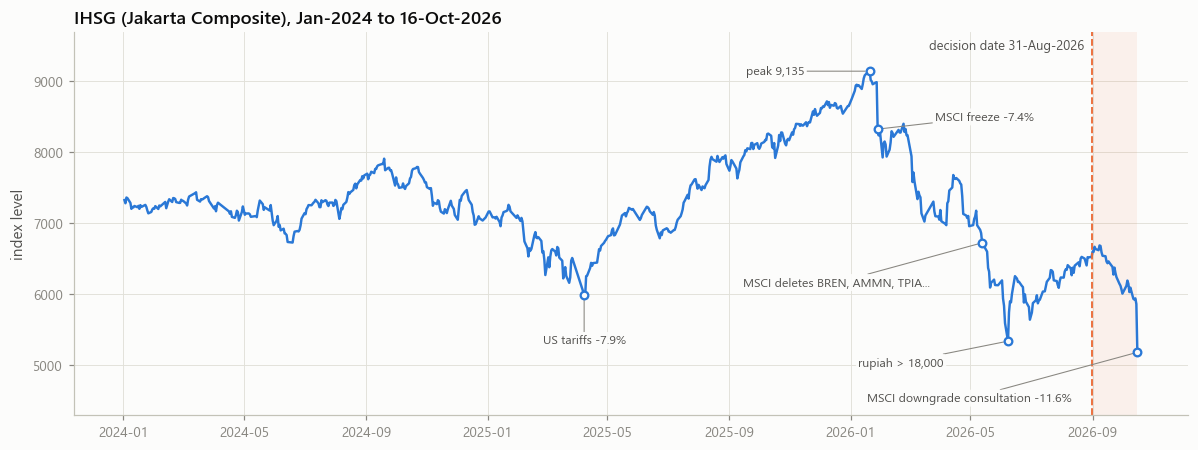

In [14]:
jk = macro_raw["JKSE"].dropna()
peak_day = jk.loc["2026"].idxmax()

fig = FG.ihsg_events(jk)
plt.show()

* IHSG peaked at **9.135** on **20-Jan-2026**
* IHSG on the decision date: **6.525 (-28.6% from the peak)**
* IHSG on **2026-10-16 : 5.185**, on **2026-10-19 : 4.997**

#### **Headline market cap is not investable market cap**

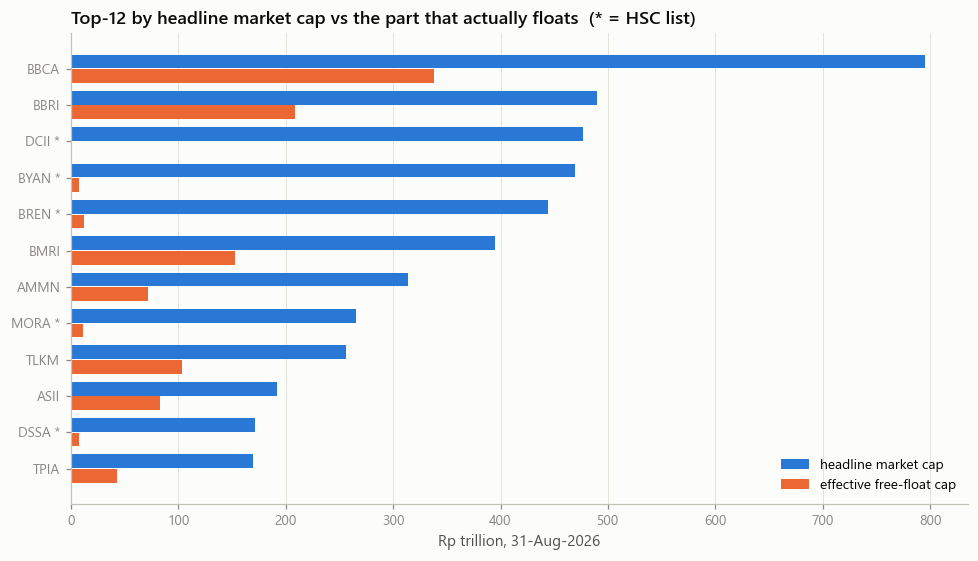

In [16]:
hsc = own["hsc_listed_by_20260831"].astype(str).str.lower().isin(["true", "1", "yes"])
free_float = own["free_float_20260731_pct"].fillna(own["free_float_pct"])
eff_float = pd.Series(np.where(hsc, own["hsc_implied_float_pct"].fillna(free_float), free_float), index=own.index)

# third-order screen, known on 31-Aug: IDX high-shareholding-concentration (HSC) list or free float < 15%
RISKY = sorted(own.index[hsc | (free_float < 15)])

t50 = top50.copy()
t50["mcap_T"] = t50["mcap_bn"] / 1e3
t50["free_float_pct"] = free_float.reindex(t50.index)
t50["eff_float_pct"] = eff_float.reindex(t50.index)
t50["hsc"] = hsc.reindex(t50.index).fillna(False)
t50["eff_float_cap_T"] = t50["mcap_T"] * t50["eff_float_pct"] / 100

head_T = t50["mcap_T"].sum()
float_T = t50["eff_float_cap_T"].sum()
risky_share = t50.loc[t50.index.isin(RISKY), "mcap_T"].sum() / head_T
hsc_share = t50.loc[t50["hsc"], "mcap_T"].sum() / head_T

fig = FG.headline_vs_float(t50, n=12)
plt.show()

* Headline market cap **Rp7.698 T**. only **Rp1.778 T (23%)** is effectively floating
* HSC-listed names : **32% of headline cap**
* Structural-risk names (HSC list or free float < 15%): 19 names = 40% of headline cap
-> ADMR, BNLI, BREN, BRIS, BYAN, CDIA, DCII, DNET, DSSA, HMSP, MLPT, MORA, MPRO, NCKL, PANI, PGUN, SRAJ, SUPR, UNVR

#### **can the stock be traded at a real price?**

In [27]:
month_end_dates = D.month_ends(close.index, start="2014-12-31", end=C.DECISION_DATE)
check_dates = month_end_dates.append(pd.DatetimeIndex([T1]))
investable, inv_feats = V2.investability(close, vol, r, check_dates)

at_t0 = inv_feats.xs(T0, level="date").reindex(TOP50)
at_t0["investable"] = investable.xs(T0, level="date").reindex(TOP50).fillna(False).astype(bool)
blocked = at_t0[~at_t0["investable"]]
blocked = pd.DataFrame({
    "median value traded (Rp bn/day)": (blocked["adv_med_63"] / 1e9).round(2),
    "zero-return days (%)": (blocked["stale_63"] * 100).round(0),
    "at the Rp50 floor": blocked["at_floor"],
})

print(f"Rules: median daily value >= Rp{V2.MIN_ADV / 1e9:.0f} bn, zero-return days < {V2.MAX_STALE:.0%}, price above the Rp{V2.MIN_PRICE_FLOOR} floor (63 sessions)")
print(f"{len(blocked)} of the 50 names fail on 31-Aug-2026. A price that does not move looks 'risk-free' to an optimizer,")
print("so without this screen a backtest rewards stale and floor-pinned stocks (e.g. GOTO at Rp50, CASA).")
display(blocked)

Rules: median daily value >= Rp5 bn, zero-return days < 20%, price above the Rp50 floor (63 sessions)
13 of the 50 names fail on 31-Aug-2026. A price that does not move looks 'risk-free' to an optimizer,
so without this screen a backtest rewards stale and floor-pinned stocks (e.g. GOTO at Rp50, CASA).


,median value traded (Rp bn/day),zero-return days (%),at the Rp50 floor
ticker,,,
DCII,0.12,35.0,False
BYAN,0.50,13.0,False
MORA,1.92,6.0,False
SRAJ,0.07,46.0,False
DNET,0.13,21.0,False
SMMA,0.04,44.0,False
MPRO,0.03,33.0,False
CASA,0.02,32.0,False
BNLI,0.11,6.0,False


#### **Who fell on the 2026 MSCI shock days (all before the decision)**

In [18]:
shock_days = {
    "28-Jan MSCI freeze": "2026-01-28",
    "21-Apr freeze kept": "2026-04-21",
    "13-May MSCI deletions": "2026-05-13",
    "21-May sell-off": "2026-05-21",
    "05-Jun sell-off": "2026-06-05",
    "09-Jun rebound": "2026-06-09",
}
jk_ret = jk.pct_change()
in_risky = np.isin(TOP50, RISKY)

rows = []
for label, day in shock_days.items():
    x = r.loc[day, TOP50]
    rows.append({
        "day (2026)": label,
        "IHSG": jk_ret.loc[day],
        "structural-risk names": x[in_risky].mean(),
        "other names": x[~in_risky].mean(),
    })
shocks = pd.DataFrame(rows).set_index("day (2026)")
shocks["gap"] = shocks["structural-risk names"] - shocks["other names"]

print("Average daily return on the 2026 MSCI shock days:")
display(shocks.style.format("{:+.1%}"))

Average daily return on the 2026 MSCI shock days:


,IHSG,structural-risk names,other names,gap
day (2026),,,,
28-Jan MSCI freeze,-7.3%,-7.3%,-6.5%,-0.7%
21-Apr freeze kept,-0.5%,-0.6%,+1.0%,-1.6%
13-May MSCI deletions,-2.0%,-2.6%,-2.5%,-0.1%
21-May sell-off,-3.5%,-4.5%,-3.9%,-0.5%
05-Jun sell-off,-4.2%,-4.6%,-3.4%,-1.3%
09-Jun rebound,+7.6%,+7.5%,+9.1%,-1.6%


The flagged names fell more on MSCI days and lagged on rebounds, but not by a large margin.    
The evidence is partial, so it is used to calibrate stress scenarios, not as a return forecast.

## **3. Predictive analytics**

In [19]:
top_pit = F.point_in_time_universe(mcap, close, vol)
SF = F.stock_daily_features(close, adj, vol, r, macro["JKSE"].pct_change(fill_method=None), mcap)
MF = F.market_daily_features(macro)
rf_daily = D.risk_free_daily(close.index)
panel, mkt = F.monthly_panel(SF, MF, top_pit, mcap, close, adj, macro["JKSE"], TOP50, rf_daily)

# on the decision date the universe is exactly the IDX top-50 list of Section 1.1
on_t0 = panel.index.get_level_values("date") == T0
panel.loc[on_t0, "in_top50"] = panel.index.get_level_values("ticker")[on_t0].isin(TOP50)

n_months = panel.index.get_level_values("date").nunique()
print(f"Panel: {len(panel):,} stock-months over {n_months} month-ends "
      f"({panel.index[0][0]:%b-%Y} to {panel.index[-1][0]:%b-%Y})")

Panel: 14,015 stock-months over 189 month-ends (Jan-2011 to Sep-2026)


In [21]:
def cagr(monthly):
    return (1 + monthly).prod() ** (12 / len(monthly)) - 1


window = panel.loc[idx[C.BACKTEST_START:C.BACKTEST_END, :], :]
ew_pit = window[window["in_top50"]].groupby(level="date")["fwd_ret"].mean()
ew_fixed = window[window.index.get_level_values("ticker").isin(TOP50)].groupby(level="date")["fwd_ret"].mean()

print("Survivorship check, equal weight 2015 - Jun 2026 (before costs):")
print(f"  point-in-time top-50: {cagr(ew_pit):+.1%} a year")
print(f"  today's top-50 list : {cagr(ew_fixed):+.1%} a year")
print("Today's list contains the stocks that later became large, so a backtest on it 'learns' to buy past winners.")

Survivorship check, equal weight 2015 - Jun 2026 (before costs):
  point-in-time top-50: +3.3% a year
  today's top-50 list : +35.9% a year
Today's list contains the stocks that later became large, so a backtest on it 'learns' to buy past winners.


#### **Return signal**

In [23]:
signal = F.xs_rank(panel, "dist_52w_high")
fwd = panel.loc[panel["in_top50"], "fwd_ret"]
pairs = pd.concat([signal.rename("signal"), fwd.rename("fwd_ret")], axis=1).dropna()
ic = pairs.groupby(level="date").apply(lambda g: g["signal"].corr(g["fwd_ret"], method="spearman"))

ic_windows = {
    "2015-2023": (C.BACKTEST_START, C.SELECTION_END),
    "2024-Jun 2026": (C.TEST_START, C.BACKTEST_END),
}
for name, (a, b) in ic_windows.items():
    x = ic.loc[a:b]
    t_stat = x.mean() / x.std() * np.sqrt(len(x))
    print(f"52-week-high signal, rank IC {name}: {x.mean():.3f} (t = {t_stat:.1f}, {len(x)} months)")

52-week-high signal, rank IC 2015-2023: 0.057 (t = 2.4, 107 months)
52-week-high signal, rank IC 2024-Jun 2026: 0.044 (t = 1.1, 30 months)


Also tried as return forecasts (walk-forward, 1-month embargo): ridge, elastic net, random forest, extra trees,
LightGBM, XGBoost, MLP, LSTM and Transformer (GPU), a news-sentiment feature (137,739 headlines), and
fundamental / macro composite scores. 

Their ICs were modest (about 0.04-0.09) and, inside the V2 mandate,
none beat the simple 52-week-high ranking, so V2 uses it; fundamentals work best as filters.

#### **Crash model learned from 17 Countries to check equity holdings**

Pooled panel: 17 markets, 5,973 country-months, 783 crash months (next-month return below -1 own standard deviation)


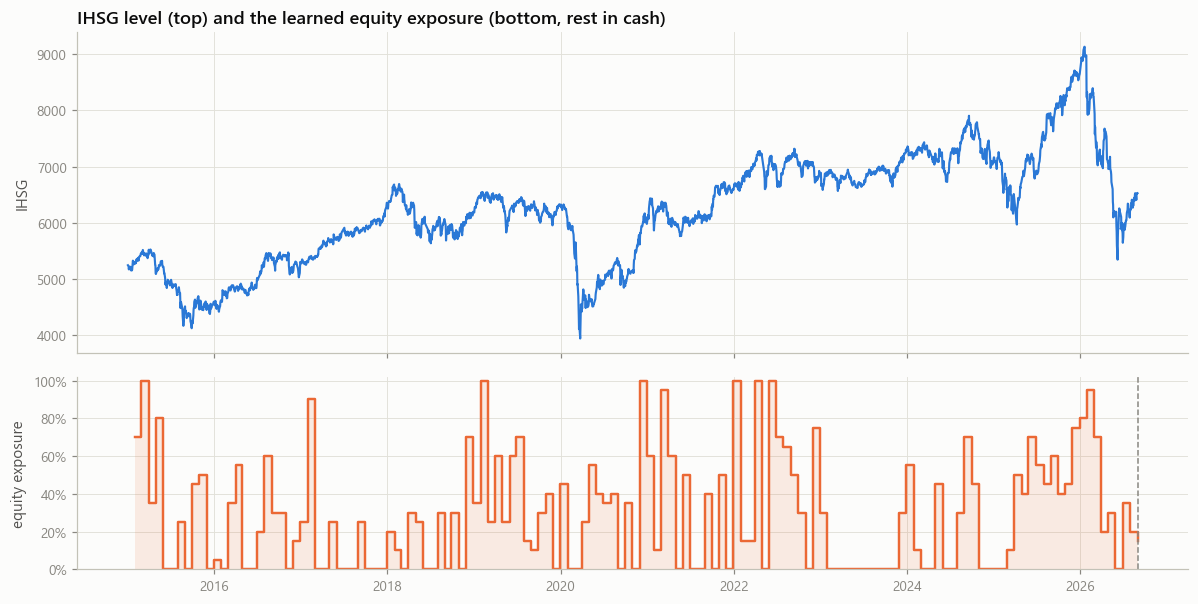

In [24]:
CP = T.build_country_panel(intl)
crash_model = T.walk_forward_exposure(CP, gamma=C.GAMMA)

# map the model's calendar month-ends onto IDX month-ends
by_month = crash_model.copy()
by_month.index = by_month.index.to_period("M")
exposure = pd.Series(by_month["exposure"].reindex(mkt.index.to_period("M")).values, index=mkt.index).dropna()

n_crash = int((CP["y_z"] < -1).sum())
at_aug = by_month.loc[T0.to_period("M")]
print(f"Pooled panel: {CP.index.get_level_values('country').nunique()} markets, {len(CP):,} country-months, {n_crash} crash months (next-month return below -1 own standard deviation)")

fig = FG.timing_panel(jk, exposure)
plt.show()

**31-Aug-2026**: crash probability 14.3% (base rate 13.1%), IHSG 3-month volatility 31% a year, utility-maximising equity share 15%; the rest earns the money-market rate


The crash probability is near normal. the low share comes from the very high current volatility.
(A random forest, nearest neighbours, LightGBM, an Indonesia-only model, trend and volatility-target rules were
 also tried, the pooled logit had the highest certainty equivalent in 2024-26)

## **4. Prescriptive analytics**

In [28]:
fund = V2.fundamentals_panel(month_end_dates, mcap, macro_raw["USDIDR"])

top_rows = panel[panel["in_top50"]].loc[idx["2014-12-31":C.DECISION_DATE, :], :]
inv_ok = investable.reindex(top_rows.index).fillna(False).astype(bool)
fund_ok = V2.fundamental_screen(fund.reindex(top_rows.index), sectors)
mask = inv_ok & fund_ok

t0_universe = top_rows.xs(T0, level="date").index
passes = mask.xs(T0, level="date").reindex(t0_universe).fillna(False)
eligible = [n for n in t0_universe if passes[n] and n not in RISKY]

print("1st order (first principles): tradable at a real price; profitable over the last 4 quarters; positive equity;")
print("   debt/equity <= 3 for non-financials. Filings are used only 75 days (interim) / 95 days (annual)")
print("   after the quarter-end, when they are public.")
print("2nd order: macro sensitivities (rupiah, oil, coal, gold, copper, US rates, foreign flows) are measured per stock")
print("   and checked for the chosen portfolio (Section 5); a 30% sector cap limits any single macro bet.")
print("3rd order: forced flows - names on the official HSC list or with free float < 15% are excluded at the decision,")
print("   and MSCI-shock multipliers enter the Monte Carlo.")
print()
print(f"31-Aug-2026: {int(passes.sum())} of 50 names pass the 1st-order screens, {len(eligible)} remain after the official screen.")

1st order (first principles): tradable at a real price; profitable over the last 4 quarters; positive equity;
   debt/equity <= 3 for non-financials. Filings are used only 75 days (interim) / 95 days (annual)
   after the quarter-end, when they are public.
2nd order: macro sensitivities (rupiah, oil, coal, gold, copper, US rates, foreign flows) are measured per stock
   and checked for the chosen portfolio (Section 5); a 30% sector cap limits any single macro bet.
3rd order: forced flows - names on the official HSC list or with free float < 15% are excluded at the decision,
   and MSCI-shock multipliers enter the Monte Carlo.

31-Aug-2026: 30 of 50 names pass the 1st-order screens, 22 remain after the official screen.


### **Walk-forward backtest of the V2 policy, 2015 – June 2026**

Reproduces the locked search result: CE 2015-23 3.13%, CE 2024-26 9.41%
Average equity share 29%, average 11.9 names, cost 1.76% a year


,CE 2015-23,CE 2024-26,CAGR,Sharpe,max drawdown
V2 policy (net of costs),3.1%,9.4%,6.3%,0.25,-13.5%
Equal weight top-50 (before costs),-2.7%,-7.3%,3.3%,0.05,-37.3%
IHSG (price index),-0.7%,-13.1%,1.1%,-0.12,-34.9%
Cash (money market),4.1%,4.5%,4.2%,nan,0.0%


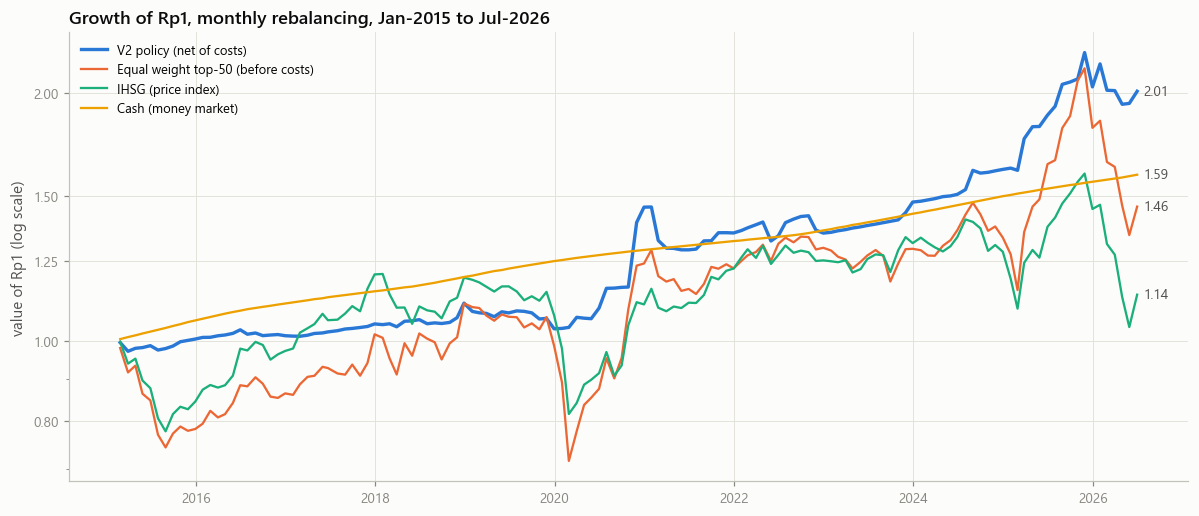

In [14]:
ctx = B.Context(panel, mkt, r, signal, mask, exposure, sectors)
bt = B.run_backtest(ctx, POLICY, start=C.BACKTEST_START, end=C.BACKTEST_END)

stats = lock["winner_stats"]
ce_sel = B.ce_return(bt.loc[:C.SELECTION_END, "net"])
ce_test = B.ce_return(bt.loc[C.TEST_START:, "net"])
assert abs(ce_sel - stats["CE_sel"]) < 1e-4 and abs(ce_test - stats["CE_test"]) < 1e-4
print(f"Reproduces the locked search result: CE 2015-23 {ce_sel:.2%}, CE 2024-26 {ce_test:.2%}")

strategies = {
    "V2 policy (net of costs)": bt["net"],
    "Equal weight top-50 (before costs)": ew_pit.reindex(bt.index),
    "IHSG (price index)": bt["ihsg"],
    "Cash (money market)": bt["rf"],
}
windows = {"2015-2023": (C.BACKTEST_START, C.SELECTION_END), "2024-Jun 2026": (C.TEST_START, C.BACKTEST_END)}

rows = {}
for name, ret in strategies.items():
    full = B.metrics(ret, bt["rf"])
    rows[name] = {
        "CE 2015-23": B.ce_return(ret.loc[windows["2015-2023"][0]:windows["2015-2023"][1]]),
        "CE 2024-26": B.ce_return(ret.loc[windows["2024-Jun 2026"][0]:windows["2024-Jun 2026"][1]]),
        "CAGR": full["CAGR"],
        "Sharpe": full["Sharpe"],
        "max drawdown": full["max_drawdown"],
    }
bt_table = pd.DataFrame(rows).T

avg_names = bt.loc[bt["exposure"] > 0, "n_names"].mean()
print(f"Average equity share {bt['exposure'].mean():.0%}, average {avg_names:.1f} names, "
      f"cost {bt['cost'].mean() * 12:.2%} a year")
display(bt_table.style.format({"CE 2015-23": "{:.1%}", "CE 2024-26": "{:.1%}", "CAGR": "{:.1%}",
                               "Sharpe": "{:.2f}", "max drawdown": "{:.1%}"}))

curves = (1 + pd.DataFrame(strategies)).cumprod()
fig = FG.equity_curves(curves, "Growth of Rp1, monthly rebalancing, Jan-2015 to Jul-2026")
plt.show()

## **5. Optimal decision on 31 August 2026**

In [ ]:
w_t0, e_t0 = B.target_weights(ctx, T0, {**POLICY, "exclude": RISKY})
w_t0 = w_t0[w_t0 > 1e-4]
w_t0 = w_t0 / w_t0.sum()

u0 = panel.xs(T0, level="date")
f0 = fund.xs(T0, level="date")
beta_m, move_m, tilt_m = V2.macro_exposures(adj, macro_raw, T0, list(w_t0.index))

holdings = pd.DataFrame({
    "sector": sectors.reindex(w_t0.index),
    "sleeve weight": w_t0,
    "portfolio weight": w_t0 * e_t0,
    "to 52w high": u0["dist_52w_high"].reindex(w_t0.index),
    "vol 3m": u0["vol_3m"].reindex(w_t0.index),
    "ROE": f0["roe"].reindex(w_t0.index),
    "E/P": f0["ep"].reindex(w_t0.index),
    "debt/equity": f0["debt_to_equity"].reindex(w_t0.index),
    "macro tilt": tilt_m.reindex(w_t0.index),
}).sort_values("sleeve weight", ascending=False)
holdings.index.name = "ticker"

print(f"DECISION 31-Aug-2026: {e_t0:.0%} in equities ({len(w_t0)} names, {holdings['sector'].nunique()} sectors), "
      f"{1 - e_t0:.0%} in a money-market fund")
display(holdings.style.format(
    {
    "sleeve weight": "{:.1%}", 
    "portfolio weight": "{:.1%}",
    "to 52w high": "{:+.1%}",
    "vol 3m": "{:.0%}", 
    "ROE": "{:.1%}", 
    "E/P": "{:.1%}", 
    "debt/equity": "{:.2f}",
    "macro tilt": "{:+.2f}"
    }
))

DECISION 31-Aug-2026: 15% in equities (11 names, 6 sectors), 85% in a money-market fund


,sector,sleeve weight,portfolio weight,to 52w high,vol 3m,ROE,E/P,debt/equity,macro tilt
ticker,,,,,,,,,
ISAT,Communication Services,10.0%,1.5%,-8.8%,64%,16.1%,7.1%,1.45,+0.00
AADI,Energy,10.0%,1.5%,-1.6%,37%,20.7%,14.9%,0.24,-0.00
ADRO,Energy,10.0%,1.5%,+0.0%,33%,10.8%,10.6%,0.22,-0.00
INDF,Consumer Staples,10.0%,1.5%,-3.9%,27%,15.1%,16.6%,0.99,-0.00
BBNI,Financials,10.0%,1.5%,-9.4%,45%,12.3%,14.2%,0.49,-0.01
UNTR,Materials,10.0%,1.5%,-22.9%,34%,12.7%,14.5%,0.27,-0.00
BMRI,Financials,10.0%,1.5%,-14.3%,40%,20.4%,14.8%,0.91,-0.00
BBRI,Financials,10.0%,1.5%,-15.5%,39%,17.9%,12.0%,0.73,-0.00
TLKM,Communication Services,10.0%,1.5%,-28.6%,53%,12.1%,6.3%,0.51,-0.00


In [ ]:
# second-order check: which macro moves the equity sleeve is exposed to (weekly betas, 3 years to 31-Aug)
FACTOR_NAMES = {
    "USDIDR": "USD/IDR (rupiah weaker = up)",
    "BRENT": "Brent oil", "COAL_ROTT": "coal",
    "GOLD": "gold", 
    "COPPER": "copper",
    "US10Y": "US 10-year yield",
    "EIDO_GAP": "foreign flows (EIDO vs IHSG in USD)"
}

sleeve_beta = beta_m.reindex(w_t0.index).mul(w_t0, axis=0).sum() * 100
macro_view = pd.DataFrame({
    "last-quarter move (sd)": move_m,
    "sleeve beta (% per sd)": sleeve_beta,
})

macro_view["effect (% per week)"] = macro_view["last-quarter move (sd)"] * macro_view["sleeve beta (% per sd)"]
macro_view.index = [FACTOR_NAMES[k] for k in macro_view.index]

print("Sensitivity of the equity sleeve's weekly return, relative to the IHSG, to a 1-sd weekly move of each factor:")
display(macro_view.style.format("{:+.2f}"))
best = macro_view["effect (% per week)"].idxmax()
worst = macro_view["effect (% per week)"].idxmin()
print(f"Largest tailwind: {best} ({macro_view.loc[best, 'effect (% per week)']:+.2f}% a week)")
print(f"largest headwind: {worst} ({macro_view.loc[worst, 'effect (% per week)']:+.2f}% a week)")
net = macro_view["effect (% per week)"].sum()
print(f"Net macro tilt {net:+.2f}% a week relative to the IHSG ({'tailwind' if net > 0 else 'headwind'}).")
print(f"The main exposure is to {worst}: if that trend continues, the sleeve lags the index; this is a third-order")
print("(forced-flow) risk that the low equity share and the 30% sector cap keep small for the whole portfolio.")

Sensitivity of the equity sleeve's weekly return, relative to the IHSG, to a 1-sd weekly move of each factor:


,last-quarter move (sd),sleeve beta (% per sd),effect (% per week)
USD/IDR (rupiah weaker = up),-0.17,-0.01,+0.00
Brent oil,-0.16,+0.32,-0.05
coal,+0.00,+0.07,+0.00
gold,-0.14,-0.09,+0.01
copper,+0.22,-0.11,-0.02
US 10-year yield,+0.60,+0.08,+0.05
foreign flows (EIDO vs IHSG in USD),-0.76,+0.33,-0.25


Largest tailwind: US 10-year yield (+0.05% a week); largest headwind: foreign flows (EIDO vs IHSG in USD) (-0.25% a week).
Net macro tilt -0.26% a week relative to the IHSG (headwind).
The main exposure is to foreign flows (EIDO vs IHSG in USD): if that trend continues, the sleeve lags the index; this is a third-order
(forced-flow) risk that the low equity share and the 30% sector cap keep small for the whole portfolio.


In [17]:
px_t0 = close.loc[:T0].ffill().iloc[-1]
book = PF.integer_lots(w_t0, e_t0, px_t0, C.CAPITAL, C.LOT, C.BUY_FEE)
book.index.name = "ticker"
invested = book["value_rp"].sum()
cash_left = C.CAPITAL - invested * (1 + C.BUY_FEE)

print(f"Order book for Rp{C.CAPITAL:,.0f} (whole 100-share lots, sized at the 31-Aug close, executed at the 1-Sep close):")
print(f"buy Rp{invested:,.0f} of shares, keep Rp{cash_left:,.0f} in the money-market fund")
BOOK_FORMAT = {"price": "{:,.0f}", "value_rp": "{:,.0f}", "target_weight": "{:.2%}", "actual_weight": "{:.2%}"}
display(book.style.format(BOOK_FORMAT))

Order book for Rp100,000,000 (whole 100-share lots, sized at the 31-Aug close, executed at the 1-Sep close):
buy Rp14,835,500 of shares, keep Rp85,142,247 in the money-market fund


,lots,shares,price,value_rp,target_weight,actual_weight
ticker,,,,,,
ADRO,5,500,"2,840","1,420,000",1.50%,1.42%
AADI,1,100,"10,825","1,082,500",1.50%,1.08%
INDF,2,200,"7,500","1,500,000",1.50%,1.50%
ISAT,6,600,"2,500","1,500,000",1.50%,1.50%
BBNI,4,400,"3,860","1,544,000",1.50%,1.54%
BMRI,3,300,"4,230","1,269,000",1.50%,1.27%
BBRI,4,400,"3,250","1,300,000",1.50%,1.30%
ICBP,1,100,"7,600","760,000",0.75%,0.76%
UNTR,1,100,"24,200","2,420,000",1.50%,2.42%


In [ ]:
# Monte Carlo stress test to 31-Dec-2026: filtered historical simulation + MSCI-shock jumps
mc_names = sorted(set(w_t0.index) | set(TOP50))
R_hist = r.loc["2015-01-01":T0, mc_names].copy()
jk_daily = macro_raw["JKSE"].loc[:C.EVAL_END].ffill().pct_change(fill_method=None).reindex(R_hist.index).fillna(0)

rng = np.random.default_rng(7)
for name in mc_names:                     # before listing: market beta x IHSG + a resampled residual
    x = R_hist[name]
    ok = x.notna()
    if ok.all():
        continue
    b = np.cov(x[ok], jk_daily[ok])[0, 1] / jk_daily[ok].var()
    resid = (x[ok] - b * jk_daily[ok]).values
    R_hist.loc[~ok, name] = b * jk_daily[~ok].values + rng.choice(resid, size=(~ok).sum())

Z, sig_next = SIM.garch_standardise(R_hist)
Z = Z.clip(-8, 8)
Z = Z - Z.mean()
sig_next = sig_next.clip(0.003, 0.08)

H = len(pd.bdate_range("2026-09-01", "2026-12-31")) - 5
rf_d = float(mkt.loc[T0, "rf_fwd"]) / 21
beta = pd.Series({n: np.cov(R_hist[n], jk_daily)[0, 1] / jk_daily.var() for n in mc_names})
mu_d = (rf_d + 0.06 / 252 * beta).clip(lower=-0.001)
blue = set(own.index[free_float >= 30])
m0 = np.array([1.15 if n in RISKY else (0.95 if n in blue else 1.0) for n in mc_names])
md = np.array([1.50 if n in RISKY else (0.70 if n in blue else 1.0) for n in mc_names])

decisions = {
    "V2 decision": (w_t0, e_t0),
    "V2 stocks, fully invested": (w_t0, 1.0),
    "Equal weight top-50": (pd.Series(1 / 50, index=TOP50), 1.0),
    "Cash": (pd.Series(dtype=float), 0.0),
}
scenarios = [
    ("current volatility", 0.0), 
    ("MSCI shock p = 0.5", 0.5), 
    ("MSCI shock p = 1.0", 1.0)
]

rows = []
for scen, p_jump in scenarios:
    family = "msci_jump" if p_jump > 0 else "fhs"
    jump = {"p": p_jump, "q_severe": 0.5, "m0": m0, "md": md}
    sims = SIM.simulate_paths(R_hist, H, 10_000, family, seed=3, Z=Z, sig_next=sig_next,
                              mu_daily=mu_d, jump=jump).astype(np.float32)
    for name, (wk, ek) in decisions.items():
        wv = wk.reindex(mc_names).fillna(0).values
        wv = wv / wv.sum() if wv.sum() > 0 else wv
        term = SIM.portfolio_terminal(sims, wv, ek, rf_d)
        dd = SIM.path_drawdown(sims, wv, ek, rf_d)
        out = SIM.risk_table(term, dd)
        out.update(decision=name, scenario=scen)
        rows.append(out)
    del sims
mc = pd.DataFrame(rows)

print(f"Monte Carlo to 31-Dec-2026: {10_000:,} joint paths per scenario, {len(mc_names)} stocks, horizon {H} sessions")
mc_views = [
    ("median", "median return"),
    ("CVaR95", "95% CVaR (average of the worst 5%)"),
    ("p_loss_10", "P(loss > 10%)"),
]
for col, label in mc_views:
    print(f"\n{label}:")
    display(mc.pivot(index="decision", columns="scenario", values=col).loc[list(decisions)][[s for s, _ in scenarios]]
            .style.format("{:.1%}"))

Monte Carlo to 31-Dec-2026: 10,000 joint paths per scenario, 50 stocks, horizon 83 sessions

median return:


scenario,current volatility,MSCI shock p = 0.5,MSCI shock p = 1.0
decision,,,
V2 decision,1.7%,1.0%,0.1%
"V2 stocks, fully invested",3.0%,-1.7%,-7.7%
Equal weight top-50,3.0%,-1.9%,-8.9%
Cash,1.5%,1.5%,1.5%



95% CVaR (average of the worst 5%):


scenario,current volatility,MSCI shock p = 0.5,MSCI shock p = 1.0
decision,,,
V2 decision,1.4%,3.0%,3.5%
"V2 stocks, fully invested",18.1%,28.7%,32.0%
Equal weight top-50,17.8%,32.0%,35.1%
Cash,-1.5%,-1.5%,-1.5%



P(loss > 10%):


scenario,current volatility,MSCI shock p = 0.5,MSCI shock p = 1.0
decision,,,
V2 decision,0.0%,0.0%,0.0%
"V2 stocks, fully invested",10.4%,26.8%,43.1%
Equal weight top-50,10.7%,28.7%,47.2%
Cash,0.0%,0.0%,0.0%


## **6. Reality check: 1 September – 16 October 2026**

Executed at the 01-Sep close, held to 16-Oct-2026 (data never used for the decision):


,return,max drawdown
V2 decision,-2.22%,-2.56%
"V2 stocks, fully invested",-18.18%,-19.59%
Equal weight top-50,-23.87%,-24.59%
Cash,+0.60%,+0.00%
IHSG,-21.44%,-22.45%


Rp100 million became Rp97,781,514.
Almost all of the difference to the market comes from the exposure decision (85% in cash).
Disclosure: the V2 rules were finalised after a first version had been reviewed on this window, so this is a
pseudo-out-of-sample check. The live decision of Section 7 is the clean test.


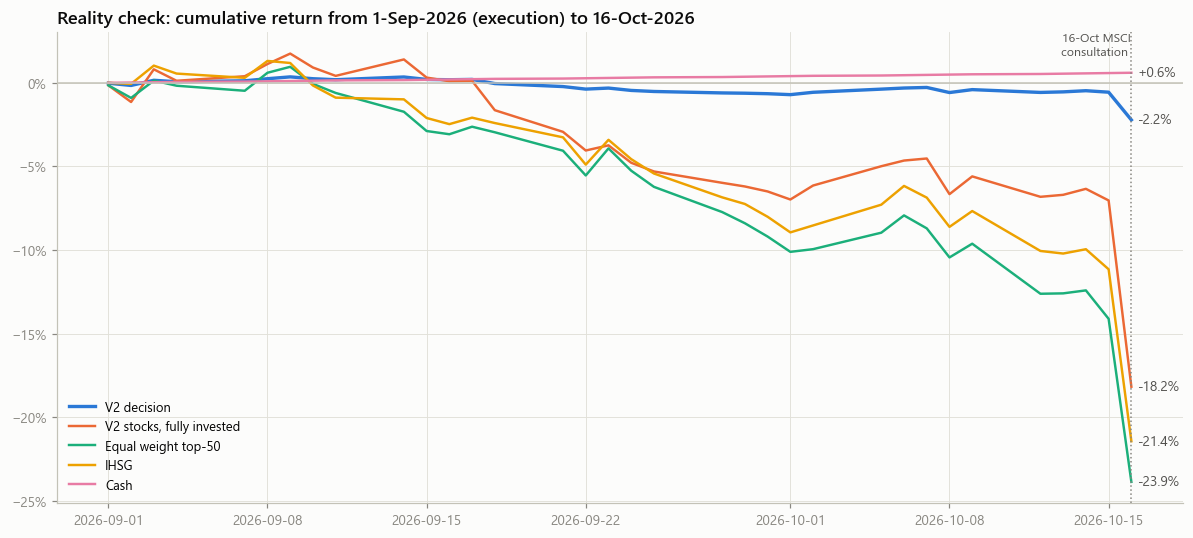

In [19]:
e_exec = close.index[close.index > T0][0]
days = close.index[(close.index >= e_exec) & (close.index <= pd.Timestamp(C.EVAL_END))]
adj_f = adj.ffill(limit=5)
r_exec = r.loc[e_exec]


def realised_path(w, e):
    cash = (1 + rf_d) ** np.arange(len(days))
    if len(w) == 0 or e == 0:
        return pd.Series(cash, index=days)
    tgt = B.apply_limit_locks(w / w.sum() * e, pd.Series(dtype=float), r_exec, px_t0, e_exec)
    e = float(tgt.sum())
    w = tgt / e
    growth = adj_f.loc[days, w.index] / adj_f.loc[e_exec, w.index]
    return (e * (growth * w).sum(axis=1) + (1 - e) * cash) * (1 - e * C.BUY_FEE)


paths = pd.DataFrame({name: realised_path(wk, ek) for name, (wk, ek) in decisions.items()})
ihsg_path = jk.reindex(days).ffill()
paths["IHSG"] = ihsg_path / ihsg_path.iloc[0]

reality = pd.DataFrame({
    "return": paths.iloc[-1] - 1,
    "max drawdown": (paths / paths.cummax() - 1).min(),
})
stock_ret = adj_f.loc[days[-1], w_t0.index] / adj_f.loc[e_exec, w_t0.index] - 1

print(f"Executed at the {e_exec:%d-%b} close, held to {days[-1]:%d-%b-%Y} (data never used for the decision):")
display(reality.style.format("{:+.2%}"))
print(f"Rp100 million became Rp{C.CAPITAL * paths['V2 decision'].iloc[-1]:,.0f}.")
print(f"Almost all of the difference to the market comes from the exposure decision ({1 - e_t0:.0%} in cash).")
print("Disclosure: the V2 rules were finalised after a first version had been reviewed on this window, so this is a")
print("pseudo-out-of-sample check. The live decision of Section 7 is the clean test.")

fig = FG.holdout_paths(paths, ["V2 decision", "V2 stocks, fully invested", "Equal weight top-50", "IHSG", "Cash"])
plt.show()

## **7. Live decision on 19 October 2026 for 30 November 2026**

19-Oct-2026: IHSG 4,997, crash probability 12.9% (base rate 13.2%), 3-month volatility 29% a year -> equity share 20%
Locked IHSG forecast for 30-Nov-2026:


,return to 30-Nov,IHSG level
5th,-17.0%,"4,148"
25th,-5.0%,"4,746"
50th,+1.9%,"5,090"
75th,+8.4%,"5,418"
95th,+19.5%,"5,972"


P(lower on 30-Nov) = 42%, P(fall > 10%) = 13%, P(rise > 10%) = 20%


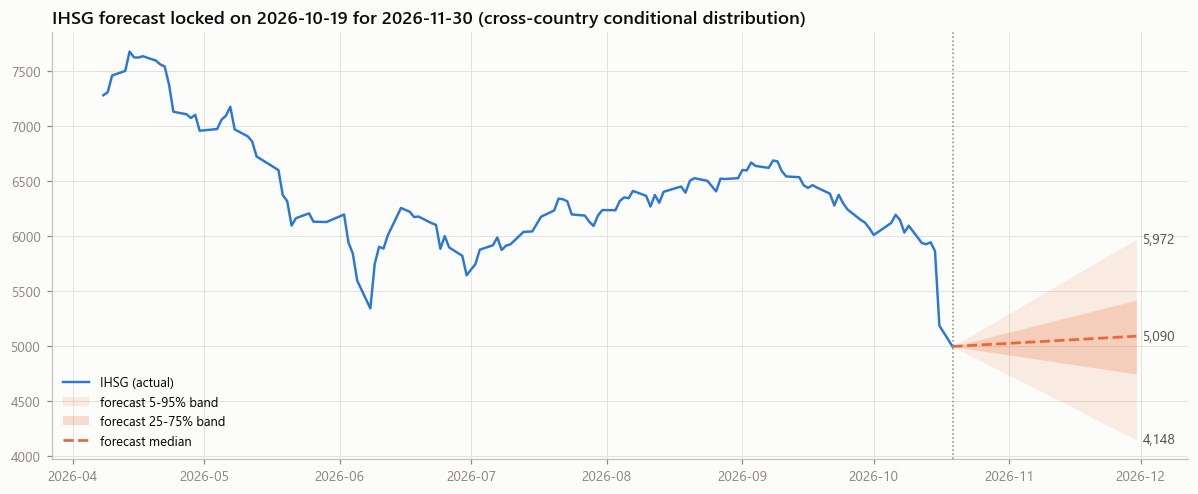

15 nearest historical situations (any country): median next-month return +1.0%, 60% rose


,,past 3m return,12m drawdown,3m volatility,next-month return
date,country,,,,
2016-06-30 00:00:00,GRC,-6.3%,-36.4%,+40.8%,+5.4%
2016-01-31 00:00:00,CHN,-21.2%,-47.0%,+37.0%,-1.8%
2014-12-31 00:00:00,GRC,-28.3%,-41.6%,+49.9%,-22.7%
2001-04-30 00:00:00,MYS,-21.9%,-38.5%,+20.7%,-2.0%
2002-10-31 00:00:00,IDN,-22.8%,-33.1%,+29.8%,+5.8%
2011-03-31 00:00:00,JPN,-4.7%,-14.0%,+33.1%,+1.0%
2000-09-30 00:00:00,IDN,-20.1%,-40.1%,+24.3%,-3.8%
1997-08-31 00:00:00,IDN,-34.3%,-33.3%,+27.5%,+10.7%


In [20]:
# state of the market at the 19-Oct close (same feature code, same rules)
exec_live = T1 + pd.offsets.BDay(1)
row = F.cross_section(SF, top_pit, mcap, close, T1, exec_live)
panel_live = pd.concat([panel, row]).sort_index()
top50_now = list(row.sort_values("mcap", ascending=False).index.get_level_values("ticker"))

# cross-country crash model, trained on labels known by 31-Aug, queried with data to 19-Oct
cp_last = CP.index.get_level_values("date").max()
cm = T.crash_model_at(CP, (cp_last, "IDN"), train_end="2026-08-31")
months = len(pd.bdate_range(T1 + pd.Timedelta(days=1), NOV30)) / 21
e_now = T.crra_best_exposure(cm["base"] * cm["vol3"] * np.sqrt(1 / 12), cm["weights"], 0.045 / 12, C.GAMMA)
scen_h = cm["base"] * cm["vol3"] * np.sqrt(months / 12)


def weighted_quantile(x, w, q):
    o = np.argsort(x)
    cw = np.cumsum(w[o])
    return float(np.interp(q, cw / cw[-1], x[o]))


ihsg_now = float(macro["JKSE"].loc[T1])
forecast = {"IHSG_now": ihsg_now}
for q in (0.05, 0.25, 0.50, 0.75, 0.95):
    ret_q = weighted_quantile(scen_h, cm["weights"], q)
    forecast[f"IHSG_ret_q{int(q * 100)}"] = ret_q
    forecast[f"IHSG_level_q{int(q * 100)}"] = ihsg_now * (1 + ret_q)
p_down = float(np.sum(cm["weights"] * (scen_h < 0)))
p_drop10 = float(np.sum(cm["weights"] * (scen_h < -0.10)))
p_rise10 = float(np.sum(cm["weights"] * (scen_h > 0.10)))

print(f"19-Oct-2026: IHSG {ihsg_now:,.0f}, crash probability {cm['p_crash']:.1%} (base rate {cm['base_rate']:.1%}), "
      f"3-month volatility {cm['vol3']:.0%} a year -> equity share {e_now:.0%}")
fc_table = pd.DataFrame(
    {"return to 30-Nov": [forecast[f"IHSG_ret_q{q}"] for q in (5, 25, 50, 75, 95)],
     "IHSG level": [forecast[f"IHSG_level_q{q}"] for q in (5, 25, 50, 75, 95)]},
    index=["5th", "25th", "50th", "75th", "95th"],
)
print("Locked IHSG forecast for 30-Nov-2026:")
display(fc_table.style.format({"return to 30-Nov": "{:+.1%}", "IHSG level": "{:,.0f}"}))
print(f"P(lower on 30-Nov) = {p_down:.0%}, P(fall > 10%) = {p_drop10:.0%}, P(rise > 10%) = {p_rise10:.0%}")

fig = FG.forecast_fan(jk, forecast, C.LIVE_DATE, C.LIVE_END)
plt.show()

near = cm["distance"].nsmallest(15)
analogs = CP.loc[near.index, ["r3", "dd12", "vol3", "y"]]
analogs.columns = ["past 3m return", "12m drawdown", "3m volatility", "next-month return"]
nxt = analogs["next-month return"]
print(f"15 nearest historical situations (any country): median next-month return {nxt.median():+.1%}, "
      f"{(nxt > 0).mean():.0%} rose")
display(analogs.head(8).style.format("{:+.1%}"))

In [ ]:
# the same V2 screens on 19-Oct
fund_now = V2.fundamentals_panel(pd.DatetimeIndex([T1]), mcap, macro["USDIDR"]).xs(T1, level="date")
inv_now = investable.xs(T1, level="date").reindex(top50_now).fillna(False).astype(bool)
fund_ok_now = V2.fundamental_screen(fund_now.reindex(top50_now), sectors)
mask_now = inv_now & fund_ok_now

hsc_any = (own["hsc_listed_by_20260831"].astype(str).str.lower().isin(["true", "1", "yes"]) | own["hsc_listed_after_20260831_only"].astype(str).str.lower().isin(["true", "1", "yes"]))
ff_now = own["free_float_pct"].fillna(own["free_float_20260731_pct"])
RISKY_NOW = sorted(own.index[hsc_any | (ff_now < 15)])

signal_live = F.xs_rank(panel_live, "dist_52w_high")
mask_live = pd.Series(mask_now.values, index=pd.MultiIndex.from_product([[T1], top50_now], names=["date", "ticker"]))
ctx_live = B.Context(panel_live, mkt, r, signal_live, mask_live, pd.Series({T1: e_now}), sectors)
w_live, e_live = B.target_weights(ctx_live, T1, {**POLICY, "exclude": RISKY_NOW})
w_live = w_live[w_live > 1e-4]
w_live = w_live / w_live.sum()

live_lock = json.load(open(C.LOCKED / "decision_live_2026-10-19.json"))
locked_w = pd.Series(live_lock["weights"])
gap = (w_live.reindex(locked_w.index.union(w_live.index)).fillna(0)
       - locked_w.reindex(locked_w.index.union(w_live.index)).fillna(0)).abs().max()
print(f"Recomputed = decision locked at {live_lock['locked_at_utc']} (max weight gap {gap:.1e}, "
      f"exposure {e_live:.0%} vs {live_lock['exposure']:.0%})")

px_now = close.loc[T1]
live_holdings = pd.DataFrame({
    "sector": sectors.reindex(w_live.index),
    "sleeve weight": w_live,
    "price 19-Oct": px_now.reindex(w_live.index),
    "ROE": fund_now["roe"].reindex(w_live.index),
    "E/P": fund_now["ep"].reindex(w_live.index),
}).sort_values("sleeve weight", ascending=False)
live_holdings.index.name = "ticker"
print(f"LIVE DECISION 19-Oct-2026: {e_live:.0%} in equities ({len(w_live)} names), "
      f"{1 - e_live:.0%} in the money-market fund")
display(live_holdings.style.format({"sleeve weight": "{:.1%}", "price 19-Oct": "{:,.0f}",
                                    "ROE": "{:.1%}", "E/P": "{:.1%}"}))

book_live = PF.integer_lots(w_live, e_live, px_now, C.CAPITAL, C.LOT, C.BUY_FEE)
print(f"Order book (execute at the 20-Oct close): Rp{book_live['value_rp'].sum():,.0f} in shares")
display(book_live.style.format(BOOK_FORMAT))
excluded = [t for t in top50_now if not mask_now.get(t, False) or t in RISKY_NOW]
print(f"{len(excluded)} of today's top-50 are excluded by the V2 rules: {', '.join(excluded)}")

Recomputed = decision locked at 2026-10-19T12:54:50Z (max weight gap 8.7e-07, exposure 20% vs 20%)
LIVE DECISION 19-Oct-2026: 20% in equities (12 names), 80% in the money-market fund


,sector,sleeve weight,price 19-Oct,ROE,E/P
ticker,,,,,
ADRO,Energy,10.0%,"2,210",12.5%,16.2%
UNTR,Materials,10.0%,"22,525",7.9%,9.7%
INDF,Consumer Staples,10.0%,"6,475",12.9%,16.8%
AADI,Energy,10.0%,"10,175",23.2%,18.3%
ASII,Industrials,10.0%,"4,130",13.0%,18.1%
ISAT,Communication Services,10.0%,"1,635",20.6%,14.2%
BBNI,Financials,10.0%,"2,960",12.5%,18.8%
BMRI,Financials,10.0%,"3,360",21.4%,19.9%
ANTM,Materials,7.5%,"2,480",24.5%,14.9%


Order book (execute at the 20-Oct close): Rp19,910,000 in shares


,lots,shares,price,value_rp,target_weight,actual_weight
BDMN,2,200,"4,400","880,000",1.00%,0.88%
INDF,3,300,"6,475","1,942,500",2.00%,1.94%
AADI,2,200,"10,175","2,035,000",2.00%,2.04%
ADRO,9,900,"2,210","1,989,000",2.00%,1.99%
UNTR,1,100,"22,525","2,252,500",2.00%,2.25%
BBNI,6,600,"2,960","1,776,000",2.00%,1.78%
BMRI,6,600,"3,360","2,016,000",2.00%,2.02%
BBRI,4,400,"2,540","1,016,000",1.00%,1.02%
ASII,5,500,"4,130","2,065,000",2.00%,2.07%
ISAT,12,1200,"1,635","1,962,000",2.00%,1.96%


27 of today's top-50 are excluded by the V2 rules: DCII, BYAN, BREN, MORA, DNET, SRAJ, SMMA, MPRO, DSSA, BRPT, EMAS, CASA, PANI, HMSP, CUAN, BNLI, MDKA, UNVR, BRIS, CDIA, ADMR, MEGA, NCKL, PGUN, GEMS, BELI, BNGA


In [ ]:
# Monte Carlo to 30-Nov: current volatility, 7% lower auto-rejection limit 
# (losses beyond it carry into the next sessions), and follow-on shocks (FTSE / rating agencies / the MSCI November review)
mc_names_l = sorted(set(w_live.index) | set(top50_now))
R_live = r.loc["2015-01-01":T1, mc_names_l].copy()
jk_live = macro["JKSE"].ffill().pct_change(fill_method=None).reindex(R_live.index).fillna(0)

rng = np.random.default_rng(11)
for name in mc_names_l:
    x = R_live[name]
    ok = x.notna()
    if ok.all():
        continue
    b = np.cov(x[ok], jk_live[ok])[0, 1] / jk_live[ok].var()
    resid = (x[ok] - b * jk_live[ok]).values
    R_live.loc[~ok, name] = b * jk_live[~ok].values + rng.choice(resid, size=(~ok).sum())

Z_l, sig_l = SIM.garch_standardise(R_live)
Z_l = Z_l.clip(-8, 8)
Z_l = Z_l - Z_l.mean()
sig_l = sig_l.clip(0.003, 0.08)

H_l = len(pd.bdate_range(T1 + pd.Timedelta(days=1), NOV30))
rf_l = 0.0475 / 252
beta_l = pd.Series({n: np.cov(R_live[n], jk_live)[0, 1] / jk_live.var() for n in mc_names_l})
mu_l = (rf_l + 0.06 / 252 * beta_l).clip(lower=-0.001)
blue_now = set(own.index[ff_now >= 30])
m0_l = np.array([1.15 if n in RISKY_NOW else (0.95 if n in blue_now else 1.0) for n in mc_names_l])
md_l = np.array([1.50 if n in RISKY_NOW else (0.70 if n in blue_now else 1.0) for n in mc_names_l])

ew_now = pd.Series(1.0, index=[t for t in top50_now if t in mc_names_l])
cap_now = row.reset_index().set_index("ticker")["mcap"].reindex(top50_now).dropna()
live_decisions = {
    "LIVE V2 decision": (w_live, e_live),
    "V2 stocks, fully invested": (w_live, 1.0),
    "Equal weight top-50": (ew_now / ew_now.sum(), 1.0),
    "Cap weight top-50 (index-like)": (cap_now / cap_now.sum(), 1.0),
    "Cash": (pd.Series(dtype=float), 0.0),
}
live_scenarios = [("no new shock", 0.0, 0.0), ("follow-on shock 30%", 0.3, 0.3), ("follow-on shock 60%", 0.6, 0.3)]

rows = []
for scen, p_jump, q_sev in live_scenarios:
    family = "msci_jump" if p_jump > 0 else "fhs"
    jump = {"p": p_jump, "q_severe": q_sev, "m0": m0_l, "md": md_l}
    sims = SIM.simulate_paths(R_live, H_l, 10_000, family, seed=5, Z=Z_l, sig_next=sig_l,
                              mu_daily=mu_l, jump=jump).astype(np.float32)
    carry = np.ones(sims.shape[0::2], dtype=np.float64)
    for h in range(sims.shape[1]):          # 7% lower limit: the rest of a larger fall is carried forward
        want = (1.0 + sims[:, h, :]) * carry
        got = np.maximum(want, 0.93)
        carry = want / got
        sims[:, h, :] = (got - 1.0).astype(np.float32)
    for name, (wk, ek) in live_decisions.items():
        wv = wk.reindex(mc_names_l).fillna(0).values
        wv = wv / wv.sum() if wv.sum() > 0 else wv
        term = SIM.portfolio_terminal(sims, wv, ek, rf_l)
        out = SIM.risk_table(term, SIM.path_drawdown(sims, wv, ek, rf_l))
        out["q05"], out["q50"], out["q95"] = np.quantile(term, [0.05, 0.5, 0.95])
        out.update(decision=name, scenario=scen)
        rows.append(out)
    del sims
mc_live = pd.DataFrame(rows)

order = list(live_decisions)
cols = [s for s, _, _ in live_scenarios]
print(f"Monte Carlo 20-Oct -> 30-Nov-2026 ({H_l} sessions, 10,000 paths per scenario)")
live_views = [("q50", "median return"), ("mean", "expected return"), ("q05", "5th percentile"), ("CVaR95", "95% CVaR")]
for col, label in live_views:
    print(f"\n{label}:")
    display(mc_live.pivot(index="decision", columns="scenario", values=col).loc[order][cols].style.format("{:+.1%}"))

sleeve = mc_live[mc_live["decision"] == "V2 stocks, fully invested"].set_index("scenario")
print("\nExpected gain on the invested sleeve (the stocks themselves) by 30-Nov: "
      + " / ".join(f"{sleeve.loc[s, 'mean']:+.1%}" for s in cols) + "  (" + " / ".join(cols) + ")")
print("Roughly zero with a wide range - which is exactly why the model holds little equity.")

Monte Carlo 20-Oct -> 30-Nov-2026 (30 sessions, 10,000 paths per scenario)

median return:


scenario,no new shock,follow-on shock 30%,follow-on shock 60%
decision,,,
LIVE V2 decision,+0.7%,+0.4%,-0.0%
"V2 stocks, fully invested",+1.4%,-0.5%,-2.3%
Equal weight top-50,+1.5%,-0.1%,-2.2%
Cap weight top-50 (index-like),+1.8%,-0.0%,-2.1%
Cash,+0.6%,+0.6%,+0.6%



expected return:


scenario,no new shock,follow-on shock 30%,follow-on shock 60%
decision,,,
LIVE V2 decision,+0.7%,+0.4%,+0.0%
"V2 stocks, fully invested",+1.5%,-0.3%,-2.2%
Equal weight top-50,+1.6%,-0.3%,-2.4%
Cap weight top-50 (index-like),+2.0%,+0.1%,-2.0%
Cash,+0.6%,+0.6%,+0.6%



5th percentile:


scenario,no new shock,follow-on shock 30%,follow-on shock 60%
decision,,,
LIVE V2 decision,-3.3%,-3.8%,-4.2%
"V2 stocks, fully invested",-18.5%,-21.0%,-23.5%
Equal weight top-50,-17.2%,-20.5%,-23.2%
Cap weight top-50 (index-like),-18.3%,-21.7%,-24.4%
Cash,+0.6%,+0.6%,+0.6%



95% CVaR:


scenario,no new shock,follow-on shock 30%,follow-on shock 60%
decision,,,
LIVE V2 decision,+4.3%,+4.9%,+5.4%
"V2 stocks, fully invested",+23.9%,+26.9%,+29.1%
Equal weight top-50,+22.7%,+26.2%,+28.9%
Cap weight top-50 (index-like),+24.0%,+27.4%,+30.0%
Cash,-0.6%,-0.6%,-0.6%



Expected gain on the invested sleeve (the stocks themselves) by 30-Nov: +1.5% / -0.3% / -2.2%  (no new shock / follow-on shock 30% / follow-on shock 60%)
Roughly zero with a wide range - which is exactly why the model holds little equity.


In [23]:
if pd.Timestamp.today().normalize() > NOV30 and close.index[-1] >= NOV30:
    print("Horizon finished: compare the realised IHSG with the forecast bands above.")
else:
    print(f"The live horizon ends on {NOV30:%d-%b-%Y}. Price data in this notebook stops on {close.index[-1]:%d-%b-%Y};")
    print("the forecast and the decision above were locked before any later price existed.")

The live horizon ends on 30-Nov-2026. Price data in this notebook stops on 19-Oct-2026;
the forecast and the decision above were locked before any later price existed.


## 8. Conclusion

In [24]:
summary = {
    "top50_headline_T": head_T, "top50_float_T": float_T, "float_share": float_T / head_T,
    "risky_n": len(RISKY), "risky_share": risky_share, "hsc_share": hsc_share, "risky_names": RISKY,
    "blocked_aug31": blocked.index.tolist(), "eligible_aug31": len(eligible),
    "ew_pit_cagr": cagr(ew_pit), "ew_fixed_cagr": cagr(ew_fixed),
    "ic_sel": float(ic.loc[C.BACKTEST_START:C.SELECTION_END].mean()),
    "ic_test": float(ic.loc[C.TEST_START:C.BACKTEST_END].mean()),
    "crash_aug31": at_aug.to_dict(), "exposure_aug31": e_t0,
    "backtest": bt_table.to_dict(orient="index"), "bt_avg_exposure": float(bt["exposure"].mean()),
    "bt_cost": float(bt["cost"].mean() * 12),
    "search": {"N": lock["N_candidates"], "PBO": lock["PBO"], "DSR": lock["DSR"]["DSR"]},
    "t50": t50[["rank", "mcap_T", "free_float_pct", "eff_float_pct", "hsc", "eff_float_cap_T"]].reset_index().to_dict(orient="records"),
    "shocks": shocks.reset_index().to_dict(orient="records"),
    "blocked_table": blocked.reset_index().to_dict(orient="records"),
    "exposure_series": {str(d.date()): float(v) for d, v in exposure.items()},
    "bt_returns": {k: {str(d.date()): float(v) for d, v in x.dropna().items()} for k, x in strategies.items()},
    "ic_t": {name: float(ic.loc[a:b].mean() / ic.loc[a:b].std() * np.sqrt(len(ic.loc[a:b]))) for name, (a, b) in ic_windows.items()},
    "weights_aug31": w_t0.round(5).to_dict(), "holdings_aug31": holdings.reset_index().to_dict(orient="records"),
    "macro_view": macro_view.to_dict(orient="index"),
    "book_aug31": book.reset_index().to_dict(orient="records"), "cash_left_aug31": cash_left,
    "mc_aug31": mc.to_dict(orient="records"),
    "reality": reality.to_dict(orient="index"), "reality_value": float(C.CAPITAL * paths["V2 decision"].iloc[-1]),
    "reality_paths": {k: {str(d.date()): float(v) for d, v in s.items()} for k, s in paths.items()},
    "stock_ret_reality": stock_ret.to_dict(),
    "live": {"exposure": e_live, "weights": w_live.round(5).to_dict(),
             "crash": {k: cm[k] for k in ("p_crash", "base_rate", "vol3")},
             "forecast": forecast, "p_down": p_down, "p_drop10": p_drop10, "p_rise10": p_rise10,
             "excluded": excluded, "holdings": live_holdings.reset_index().to_dict(orient="records"),
             "mc": mc_live.to_dict(orient="records"),
             "analogs": analogs.reset_index().astype(str).to_dict(orient="records"),
             "analogs_median": float(analogs["next-month return"].median()),
             "analogs_up": float((analogs["next-month return"] > 0).mean())},
}
json.dump(summary, open(C.OUT / "results_v2.json", "w"), indent=1, default=float)

print(f"1. Public data: the 50 largest IDX stocks are worth Rp{head_T:,.0f} T on paper, "
      f"but only {float_T / head_T:.0%} of that floats; {len(RISKY)} names are structurally risky.")
print(f"2. Descriptive: stale or illiquid prices ({len(blocked)} names) and survivorship "
      f"({cagr(ew_fixed):+.1%} vs {cagr(ew_pit):+.1%} a year) would fool a naive backtest.")
print(f"3. Predictive: return forecasts are weak (IC about {ic.loc[C.BACKTEST_START:C.SELECTION_END].mean():.2f}); "
      "the cross-country crash model drives the exposure.")
print(f"4. Prescriptive: V2 = first-principles screens + 52-week-high max-Sharpe portfolio + learned exposure "
      f"(PBO {lock['PBO']:.0%}).")
print(f"5. Decision 31-Aug-2026: {e_t0:.0%} equities in {len(w_t0)} liquid, profitable names; "
      f"1-Sep to 16-Oct: {reality.loc['V2 decision', 'return']:+.1%} vs IHSG {reality.loc['IHSG', 'return']:+.1%}.")
print(f"6. Live 19-Oct-2026: {e_live:.0%} equities; IHSG median forecast for 30-Nov {forecast['IHSG_level_q50']:,.0f} "
      f"(90% band {forecast['IHSG_level_q5']:,.0f}-{forecast['IHSG_level_q95']:,.0f}).")
print("\nAll numbers are saved to outputs/results_v2.json")

1. Public data: the 50 largest IDX stocks are worth Rp7,698 T on paper, but only 23% of that floats; 19 names are structurally risky.
2. Descriptive: stale or illiquid prices (13 names) and survivorship (+35.9% vs +3.3% a year) would fool a naive backtest.
3. Predictive: return forecasts are weak (IC about 0.06); the cross-country crash model drives the exposure.
4. Prescriptive: V2 = first-principles screens + 52-week-high max-Sharpe portfolio + learned exposure (PBO 29%).
5. Decision 31-Aug-2026: 15% equities in 11 liquid, profitable names; 1-Sep to 16-Oct: -2.2% vs IHSG -21.4%.
6. Live 19-Oct-2026: 20% equities; IHSG median forecast for 30-Nov 5,090 (90% band 4,148-5,972).

All numbers are saved to outputs/results_v2.json
